# [GSE52778](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE52778)

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Created: 2023-08-25
> - Modified: 2025-02-15

# 1. Experimental Design

> Human Airway Smooth Muscle Transcriptome Changes in Response to Asthma Medications.
> - Himes BE, Jiang X, Wagner P, Hu R, Wang Q, et al. (2014) RNA-Seq Transcriptome Profiling Identifies CRISPLD2 as a Glucocorticoid Responsive Gene that Modulates Cytokine Function in Airway Smooth Muscle Cells. PLOS ONE 9(6): e99625. https://doi.org/10.1371/journal.pone.0099625.
> - poly(A) RNA-seq
> - TruSeq RNA Sample Prep Kit v2
> - Illumina HiSeq 2000, PE75
> - GRCh38

| Sample | Organism | Cell | Source | Treatment | Batch | Patient |
| - | - | - | - | - | - | - |
| Control | Homo sapiens | ASM | Airway smooth muscle cells | Control | Inter-individual | rep1~4 |
| Albuterol | Homo sapiens | ASM | Airway smooth muscle cells | 1 μM Albuterol for 18h | Inter-individual | rep1~4 |
| Dexamethasone | Homo sapiens | ASM | Airway smooth muscle cells | 1 μM Dexamethasone for 18h | Inter-individual | rep1~4 |
| Albuterol & Dexamethasone | Homo sapiens | ASM | Airway smooth muscle cells | 1 μM Albuterol & Dexamethasone for 18h | Inter-individual | rep1~4 |

# 2. Preprocessing

In [1]:
library(tidyverse)
suppressPackageStartupMessages(library(limma))
suppressPackageStartupMessages(library(edgeR))
suppressPackageStartupMessages(library(DESeq2))
suppressPackageStartupMessages(library(ggrepel))
suppressPackageStartupMessages(library(pheatmap))
suppressPackageStartupMessages(library(patchwork))
suppressPackageStartupMessages(library(RColorBrewer))

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


## 1). Import Data

In [2]:
data_dir <- "~/dataset_1/bulk_omics/rnaseq_Hs_ASM_Dex_GSE52778"

In [3]:
raw_counts <- file.path(data_dir, "GSE52778_raw_counts_GRCh38.p13_NCBI.tsv.gz") |>
    read.table(header = TRUE, sep = "\t", row.names = 1) |> 
    as.matrix()

dim(raw_counts)

[1] 39376    16

In [4]:
coldata <- colnames(raw_counts) |>
    tibble(Accession = _) |>
    mutate(
        Patient = c("N61311", "N052611", "N080611", "N061011") |> 
            rep(each = 4) |> 
            factor(levels = c("N61311", "N052611", "N080611", "N061011")), 
        Group = c("Control", "Dex", "Alb", "AlbDex") |> rep(times = 4) |> 
            factor(levels = c("Control", "Dex", "Alb", "AlbDex")), 
        sample = paste(Patient, Group, sep = "_")) |> 
    arrange(Patient, Group) |>
    column_to_rownames("sample")

coldata

,Accession,Patient,Group
,<chr>,<fct>,<fct>
N61311_Control,GSM1275862,N61311,Control
N61311_Dex,GSM1275863,N61311,Dex
N61311_Alb,GSM1275864,N61311,Alb
N61311_AlbDex,GSM1275865,N61311,AlbDex
N052611_Control,GSM1275866,N052611,Control
N052611_Dex,GSM1275867,N052611,Dex
N052611_Alb,GSM1275868,N052611,Alb
N052611_AlbDex,GSM1275869,N052611,AlbDex
N080611_Control,GSM1275870,N080611,Control


In [5]:
anno_gene <- file.path(data_dir, "Human.GRCh38.p13.annot.tsv.gz") |>
    data.table::fread(header = TRUE, sep = "\t", quote = "") |>
    select(GeneID, symbol = Symbol, type = GeneType, basepairs = Length) |>
    mutate(GeneID = as.character(GeneID)) |> 
    column_to_rownames("GeneID") |>
    DataFrame()

In [6]:
colnames(raw_counts) <- rownames(coldata)[
    match(colnames(raw_counts), coldata$Accession)]

raw_counts <- raw_counts[, rownames(coldata)]

## 2). Object Construction

In [7]:
eSet <- SummarizedExperiment(
    assays = list(counts = raw_counts), 
    rowData = anno_gene, colData = coldata)

eSet

class: SummarizedExperiment 
dim: 39376 16 
metadata(0):
assays(1): counts
rownames(39376): 100287102 653635 ... 4576 4571
rowData names(3): symbol type basepairs
colnames(16): N61311_Control N61311_Dex ... N061011_Alb N061011_AlbDex
colData names(3): Accession Patient Group

In [8]:
dds <- DESeqDataSetFromMatrix(
    countData = raw_counts, rowData = anno_gene, 
    colData = coldata, design = ~ Patient + Group)
dds

class: DESeqDataSet 
dim: 39376 16 
metadata(1): version
assays(1): counts
rownames(39376): 100287102 653635 ... 4576 4571
rowData names(3): symbol type basepairs
colnames(16): N61311_Control N61311_Dex ... N061011_Alb N061011_AlbDex
colData names(3): Accession Patient Group

In [9]:
dgel <- DGEList(
    counts = raw_counts, genes = anno_gene, 
    samples = coldata, group = coldata$Group)

## 3). Low-Count Filtering

> - Filter low expressed genes to reduce the size of the object and increase the speed of the function

In [10]:
keep <- rowSums(assay(eSet) >= 10) >= 4
# keep <- rowSums(counts(dds) >= 10) >= 4

tab <- table(keep)

cat(
    "Filtered genes summary:\n",
    "Pass:", tab["TRUE"], "\n",
    "Remove:", tab["FALSE"], "\n",
    "Retention rate:", round(tab["TRUE"]/sum(tab)*100, 2), "%\n"
)

eSet <- eSet[keep, ]
dds <- dds[keep, ]

Filtered genes summary:
 Pass: 17544 
 Remove: 21832 
 Retention rate: 44.56 %


In [11]:
design <- model.matrix(~ group + Patient, data = dgel$samples)
keep <- filterByExpr(dgel, design = design)

tab <- table(keep)

cat(
    "Filtered genes summary:\n",
    "Pass:", tab["TRUE"], "\n",
    "Remove:", tab["FALSE"], "\n",
    "Retention rate:", round(tab["TRUE"]/sum(tab)*100, 2), "%\n"
)

dgel <- dgel[keep, , keep.lib.sizes = FALSE]
# Normalize Library Sizes
dgel <- normLibSizes(dgel)

Filtered genes summary:
 Pass: 17662 
 Remove: 21714 
 Retention rate: 44.85 %


# 3. Normalization

In [12]:
tpm <- assay(eSet) |>
    sweep(1, rowData(eSet)$basepairs, FUN = "/") |>
    (\(rpk) sweep(rpk, 2, colSums(rpk), FUN = "/") * 1e6)()

In [13]:
rld <- rlog(dds, blind = FALSE)

In [14]:
dds <- estimateSizeFactors(dds)
norm_fpkm <- fpkm(dds, robust = TRUE)

In [15]:
norm_cpm <- cpm(dgel, normalized.lib.sizes = TRUE, log = FALSE)

In [16]:
design <- model.matrix(~ group + Patient, data = dgel$samples)
norm_v <- voom(dgel, design, plot = FALSE)

In [17]:
suppressPackageStartupMessages(library(vsn))

In [18]:
common_theme <- theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [19]:
p1 <- meanSdPlot(log2(counts(dds) + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = expression(-log[2](Count+1))) + 
    common_theme
p2 <- meanSdPlot(log2(tpm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = expression(-log[2](TPM+1))) + 
    common_theme
p3 <- meanSdPlot(assay(rld), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "rlog") + 
    common_theme
p4 <- meanSdPlot(log2(norm_fpkm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "DESeq2, FPKM") + 
    common_theme
p5 <- meanSdPlot(log2(norm_cpm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "edgeR's TMM, CPM") + 
    common_theme
p6 <- meanSdPlot(norm_v$E, ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "limma's voom") + 
    common_theme

Warning message:
“`aes_string()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`.
ℹ See also `vignette("ggplot2-in-packages")` for more information.
ℹ The deprecated feature was likely used in the vsn package.
  Please report the issue to the authors.”


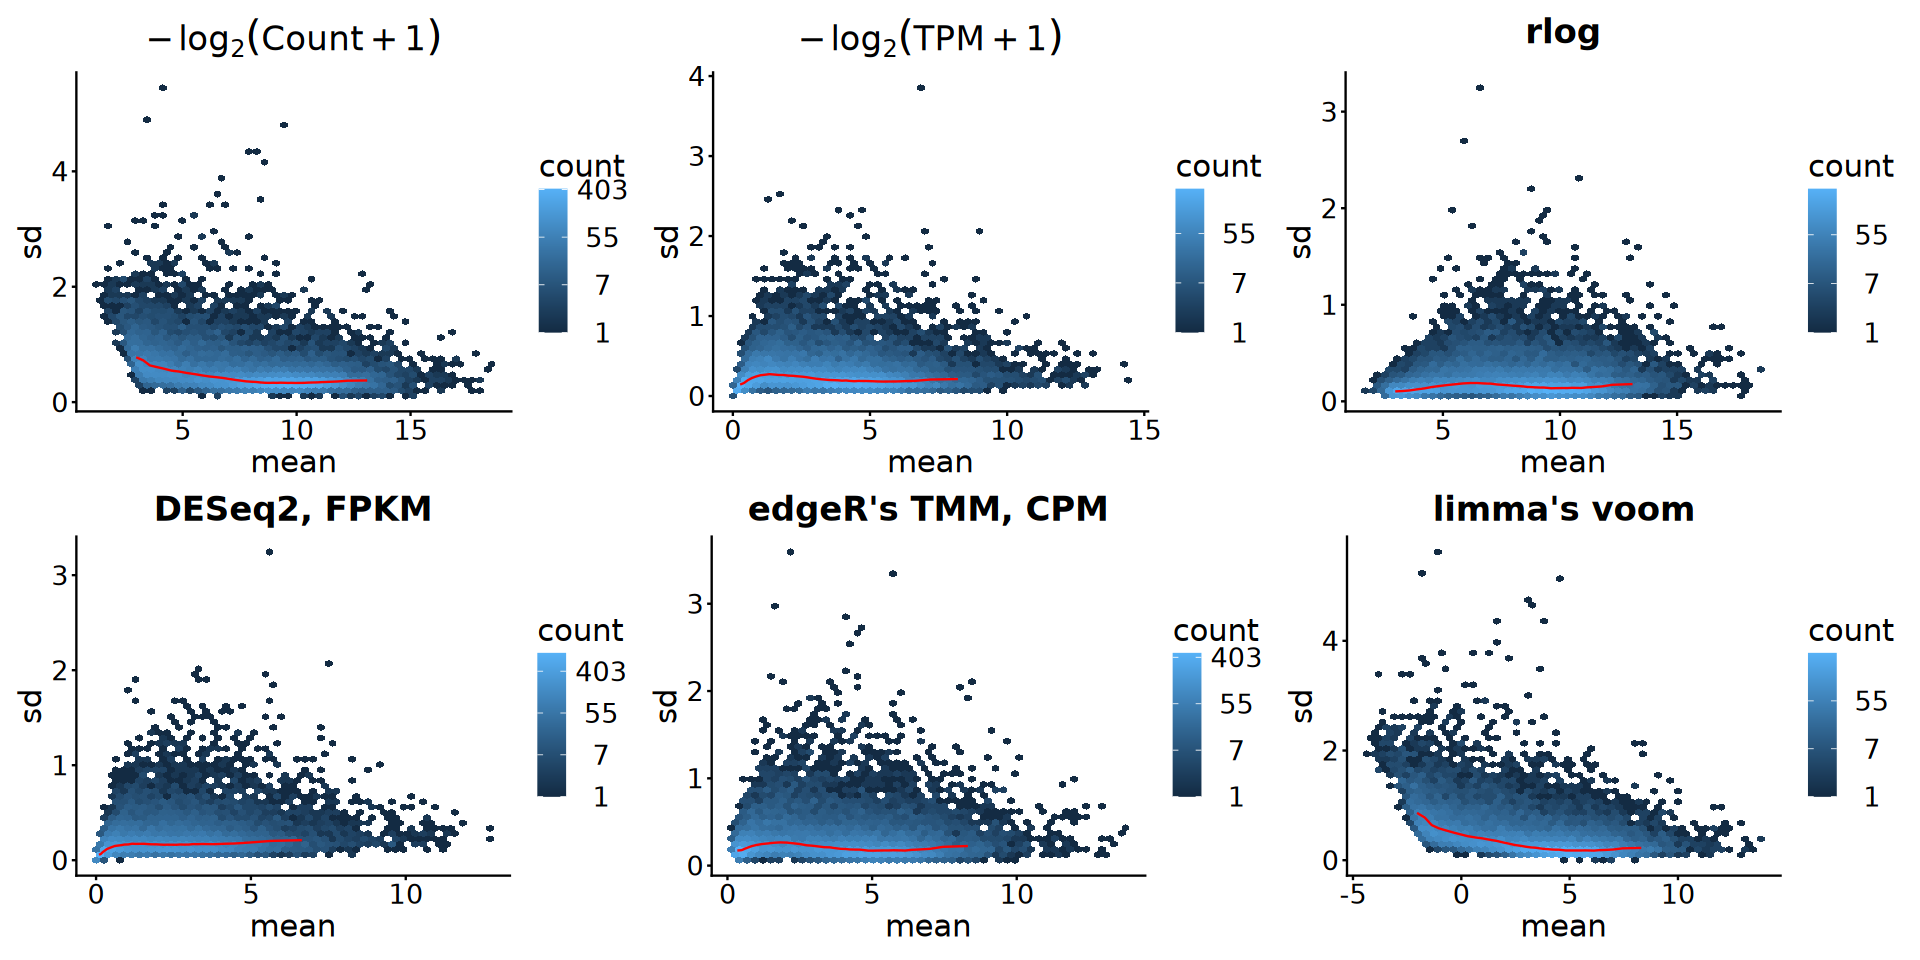

In [20]:
options(repr.plot.width = 16, repr.plot.height = 8)
(p1 + p2 + p3) / (p4 + p5 + p6)

# 4. Exploration

In [21]:
norm_mat <- log2(tpm + 1)
norm_vs <- assay(rld)

### 1). Overview

In [22]:
plot_df <- colData(eSet) |> as.data.frame() |>
    arrange(Group, Patient) |> 
    rownames_to_column(var = "Sample") |>
    mutate(librarySize = colSums(assay(eSet))[Sample])

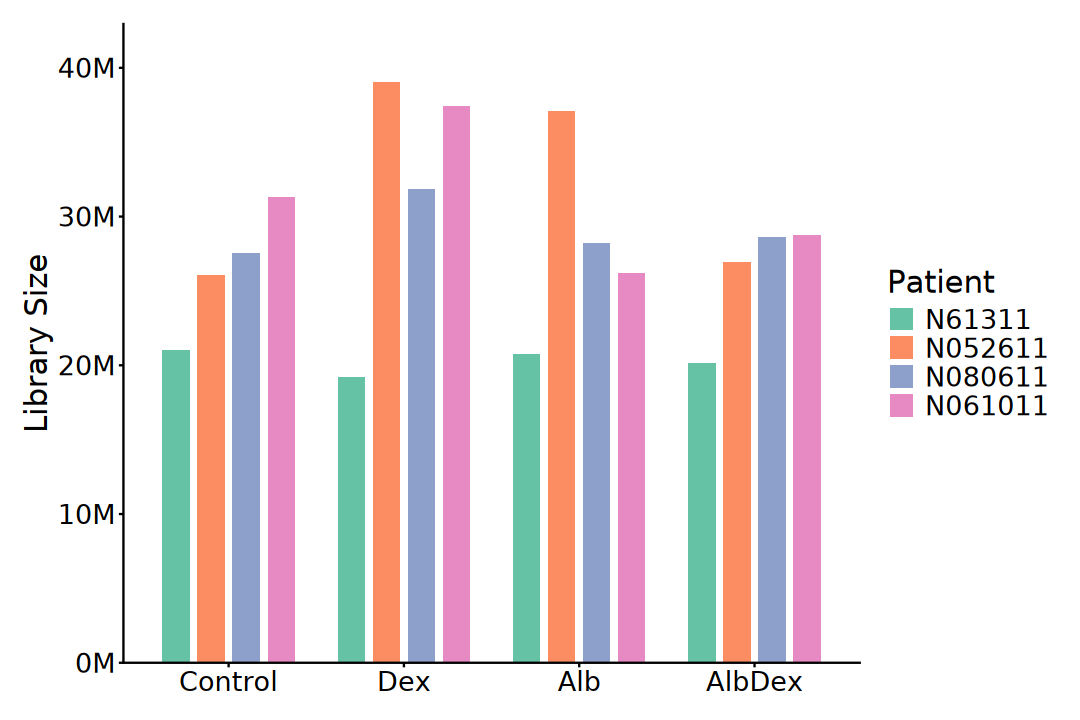

In [23]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(plot_df, aes(x = Group, y = librarySize, group = Patient)) +
    geom_bar(
        aes(fill = Patient), stat = "identity",
        position = position_dodge(width = 0.8),
        width = 0.6, linewidth = 1.5) +
    scale_y_continuous(
        labels = scales::label_number(scale = 1e-6, suffix = "M"),
        limits = c(0, NA), expand = expansion(mult = c(0, 0.1))) +
    scale_fill_brewer(palette = "Set2") +
    labs(x = NULL, y = "Library Size") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18),
        legend.text = element_text(size = 16),
        legend.position = "right",
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

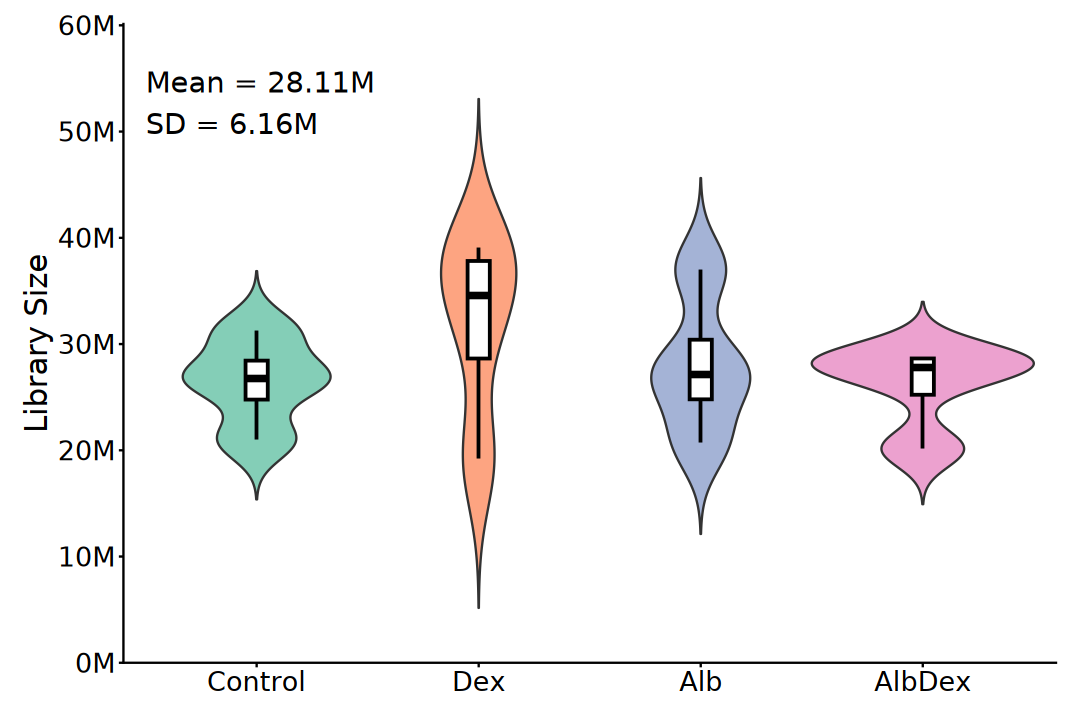

In [24]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(plot_df, aes(x = Group, y = librarySize)) +
    geom_violin(
        aes(fill = Group), width = 1, alpha = 0.8,
        trim = FALSE, show.legend = FALSE) +
    geom_boxplot(
        color = "black", fill = "white", width = 0.1, 
        linewidth = 0.8, show.legend = FALSE) +
    annotate(
        geom = "text", x = .5, y = max(plot_df$librarySize) * 1.4,
        label = paste0("Mean = ", round(mean(plot_df$librarySize) / 1e6 , 2), "M"),
        hjust = 0, size = 6) +
    annotate(
        geom = "text", x = .5, y = max(plot_df$librarySize) * 1.3,
        label = paste0("SD = ", round(sd(plot_df$librarySize) * 1e-6 , 2), "M"),
        hjust = 0, size = 6) +
    scale_y_continuous(
        labels = scales::label_number(scale = 1e-6, suffix = "M"), 
        limits = c(0, NA), expand = expansion(mult = c(0, 0.1))) +
    scale_fill_brewer(palette = "Set2") +
    labs(x = NULL, y = "Library Size") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

## 2). PCA

In [25]:
top_var_idx <- norm_mat |>
    rowSds() |>
    # (\(m) rowSds(m) / rowMeans2(m))() |> # CV
    tibble::enframe(name = "row", value = "sd") |>
    slice_max(order_by = sd, n = 2000) |>
    pull(row)
# CV can eliminate the bias that "high abundance tends to have large variance".

In [26]:
pca_res <- norm_mat[top_var_idx, ] |> t() |> 
    prcomp(center = TRUE, scale. = FALSE)

per_var <- round(100 * pca_res$sdev^2 / sum(pca_res$sdev^2), 2)

pca_df <- merge(pca_res$x, colData(eSet), by = "row.names")

In [27]:
p1 <- ggplot(pca_df, aes(PC1, PC2)) +
    geom_point(aes(color = Group, shape = Patient), size = 5) +
    scale_color_brewer(palette = "Set1") +
    labs(
        title = bquote("PCA for" ~ -log[2](TPM+1)), 
        x = paste0("PC1: ", per_var[1], "% variance"),
        y = paste0("PC2: ", per_var[2], "% variance")) +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [28]:
pca_res <- plotPCA(
    rld, intgroup = c("Group", "Patient"), 
    ntop = 2000, returnData = TRUE)

per_var <- round(100 * attr(pca_res, "percentVar"))

using ntop=2000 top features by variance



In [29]:
p2 <- ggplot(pca_res, aes(PC1, PC2)) +
    geom_point(aes(color = Group, shape = Patient), size = 5) +
    scale_color_brewer(palette = "Set1") +
    labs(
        title = "PCA for rlog", 
        x = paste0("PC1: ", per_var[1], "% variance"),
        y = paste0("PC2: ", per_var[2], "% variance")) +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [30]:
# Generalized principal component analysis (GLM-PCA)
# suppressPackageStartupMessages(library(glmpca))
gpca <- glmpca::glmpca(assay(eSet)[top_var_idx, ], L = 2)

gpca_df <- merge(gpca$factors, colData(eSet), by = "row.names")

In [31]:
p3 <- ggplot(gpca_df, aes(dim1, dim2)) +
    geom_point(aes(color = Group, shape = Patient), size = 5) +
    scale_color_brewer(palette = "Set1") +
    labs(title = "GLM-PCA for raw count", x = "PC1", y = "PC2") +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

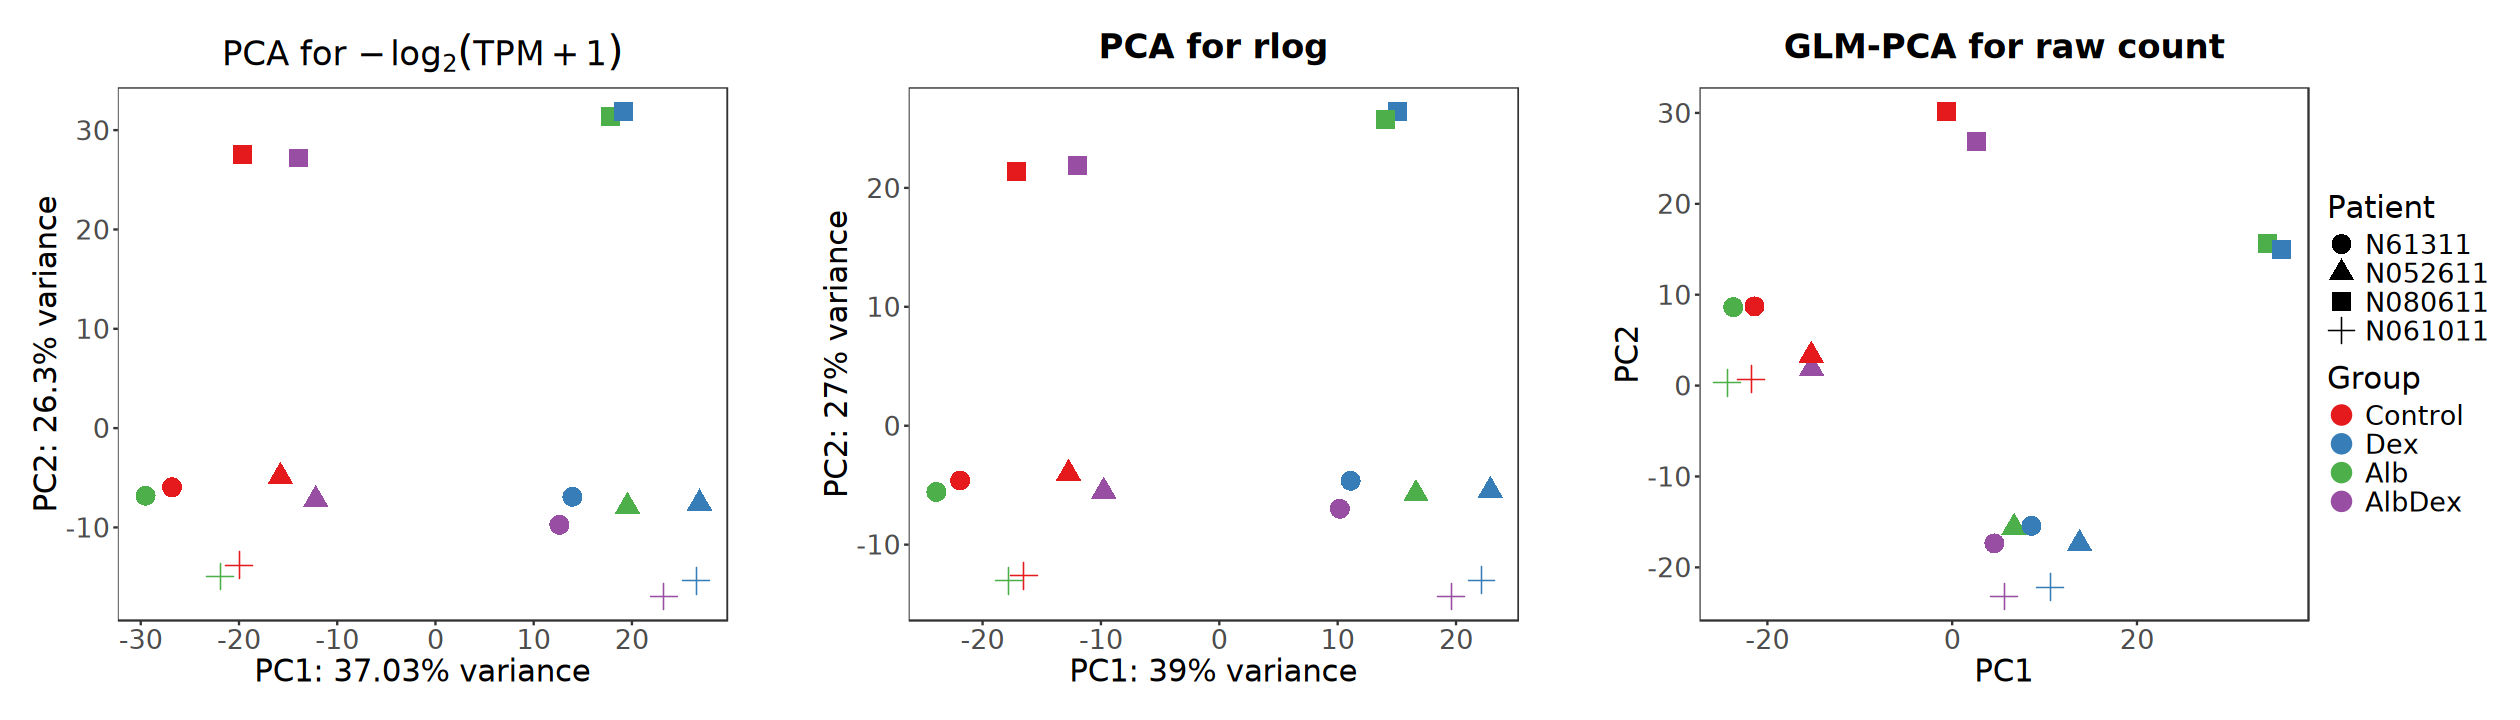

In [32]:
options(repr.plot.width = 21, repr.plot.height = 6)

p1 + plot_spacer() + p2 + plot_spacer() + p3 +
    plot_layout(nrow = 1, guides = "collect", 
                widths = c(1, 0.05, 1, 0.05, 1))

## 3). MDS

> Multidimensional scaling

In [33]:
dist_mat <- norm_vs[top_var_idx, ] |> t() |> dist()

mds <- colData(eSet) |> as.data.frame() |>
    cbind(cmdscale(as.matrix(dist_mat)))

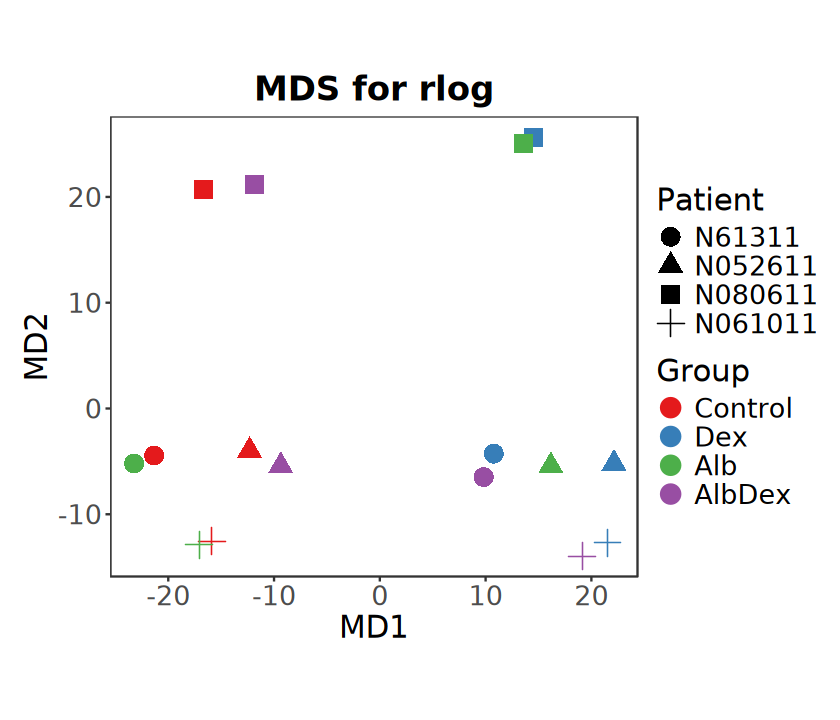

In [34]:
options(repr.plot.width = 7, repr.plot.height = 6)

ggplot(mds, aes(x = `1`, y = `2`)) +
    geom_point(aes(color = Group, shape = Patient), size = 5) +
    scale_color_brewer(palette = "Set1") +
    coord_fixed() + 
    labs(title = "MDS for rlog", x = "MD1", y = "MD2") +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

## 4). PCoA

> Principal coordinate analysis

In [35]:
# 1. Calculate Bray-Curtis distance on the transposed count matrix
dist_mat <- norm_vs[top_var_idx, ] |> t() |> 
    vegan::vegdist(method = "bray")

# 2. Run PCoA
pcoa_res <- cmdscale(dist_mat, k = 2, eig = TRUE)

# 3. Prepare data for plot
pcoa_df <- merge(pcoa_res$points, colData(eSet), by = "row.names")

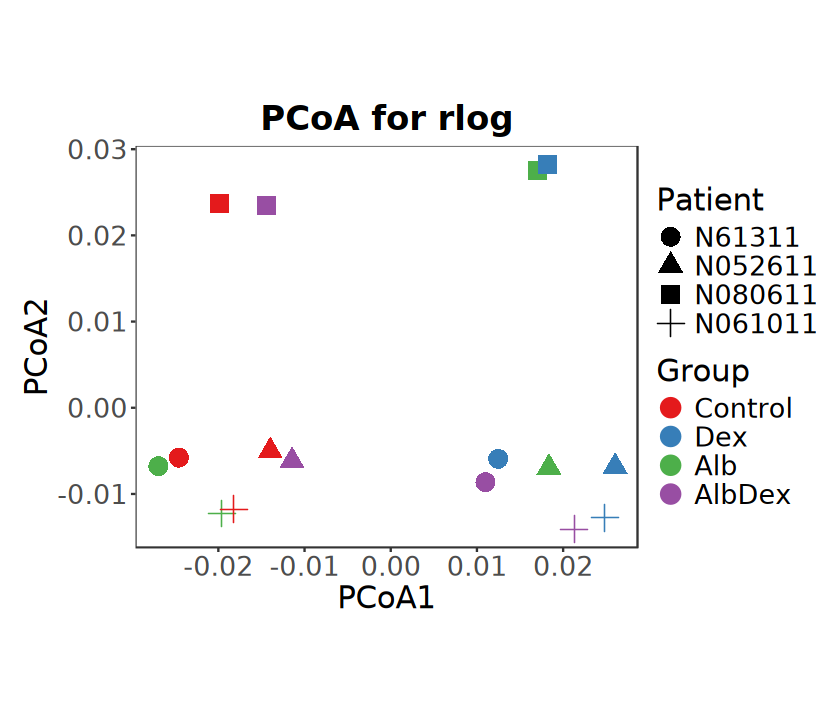

In [36]:
options(repr.plot.width = 7, repr.plot.height = 6)

ggplot(pcoa_df, aes(x = V1, y = V2)) +
    geom_point(aes(color = Group, shape = Patient), size = 5) +
    scale_color_brewer(palette = "Set1") +
    coord_fixed() + 
    # ggtitle(bquote("PCoA for" ~ -log[2](TPM+1))) + 
    ggtitle("PCoA for rlog") + 
    labs(x = "PCoA1", y = "PCoA2") +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

## 5). Sample Distance

In [37]:
ac <- colData(eSet) |> as.data.frame() |>
    dplyr::select(Patient, Group)

In [38]:
group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(eSet$Group)),
    levels(eSet$Group))
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(eSet$Patient)),
    levels(eSet$Patient))

anno_colors <- list(
    Group = group_colors,
    Patient = replicate_colors)

colors <- colorRampPalette(brewer.pal(9, "Blues"))(255)

In [39]:
dist_mat <- norm_vs[top_var_idx, ] |> t() |> dist()

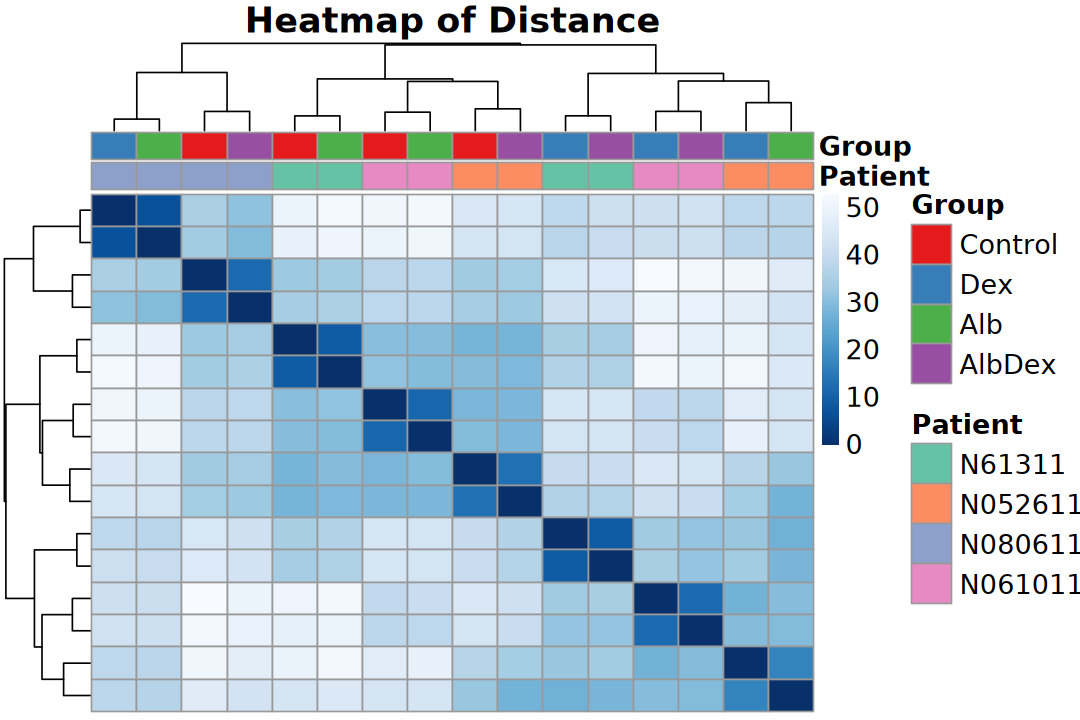

In [40]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(dist_mat),
    clustering_distance_rows = dist_mat,
    clustering_distance_cols = dist_mat,
    annotation_col = ac, col = rev(colors), 
    annotation_colors = anno_colors,
    main = "Heatmap of Distance", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

In [41]:
# This measure of dissimilarity between counts also takes the inherent variance structure 
# of counts into consideration when calculating the distances between samples. 
# The PoissonDistance function takes the original count matrix (not normalized) with samples
# as rows instead of columns, so we need to transpose the counts in dds.
# Calculating sample distances is to use the Poisson Distance

# suppressPackageStartupMessages(library(PoiClaClu))
poisd <- assay(eSet)[top_var_idx, ] |> t() |> 
    PoiClaClu::PoissonDistance()

dist_mat <- poisd$dd |> as.matrix()

colnames(dist_mat) <- colnames(eSet)

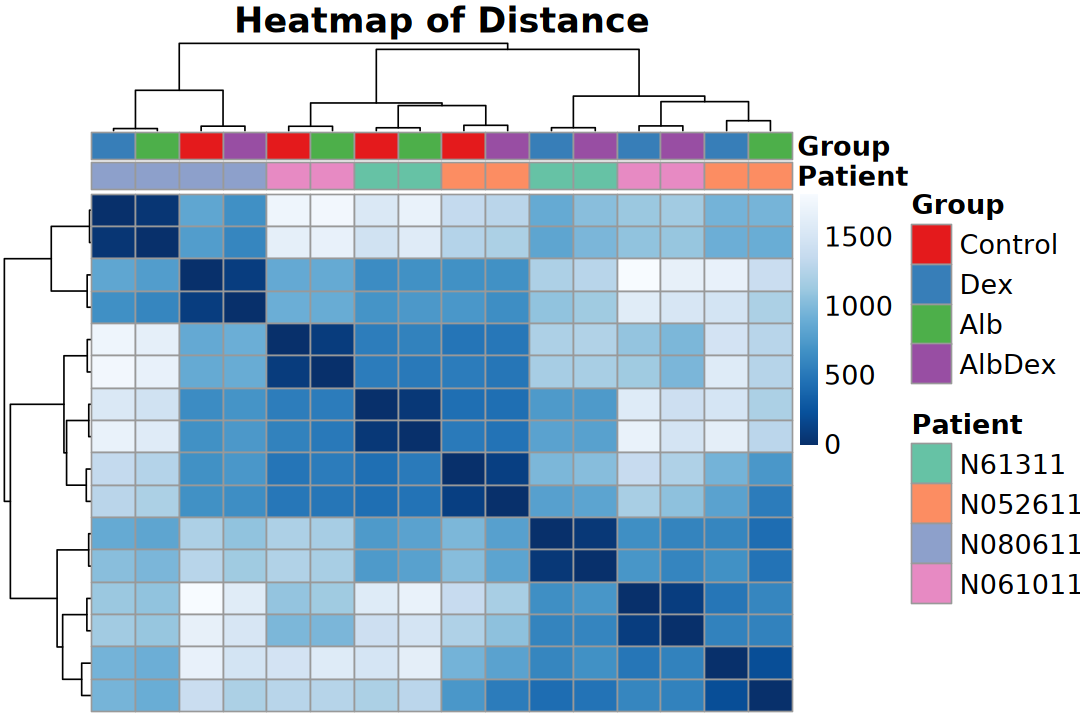

In [42]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(dist_mat),
    clustering_distance_rows = poisd$dd,
    clustering_distance_cols = poisd$dd,
    annotation_col = ac, col = rev(colors), 
    annotation_colors = anno_colors,
    main = "Heatmap of Distance", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

## 6). Sample Correlation

In [43]:
cor_mat <- cor(norm_vs[top_var_idx, ], method = "spearman")

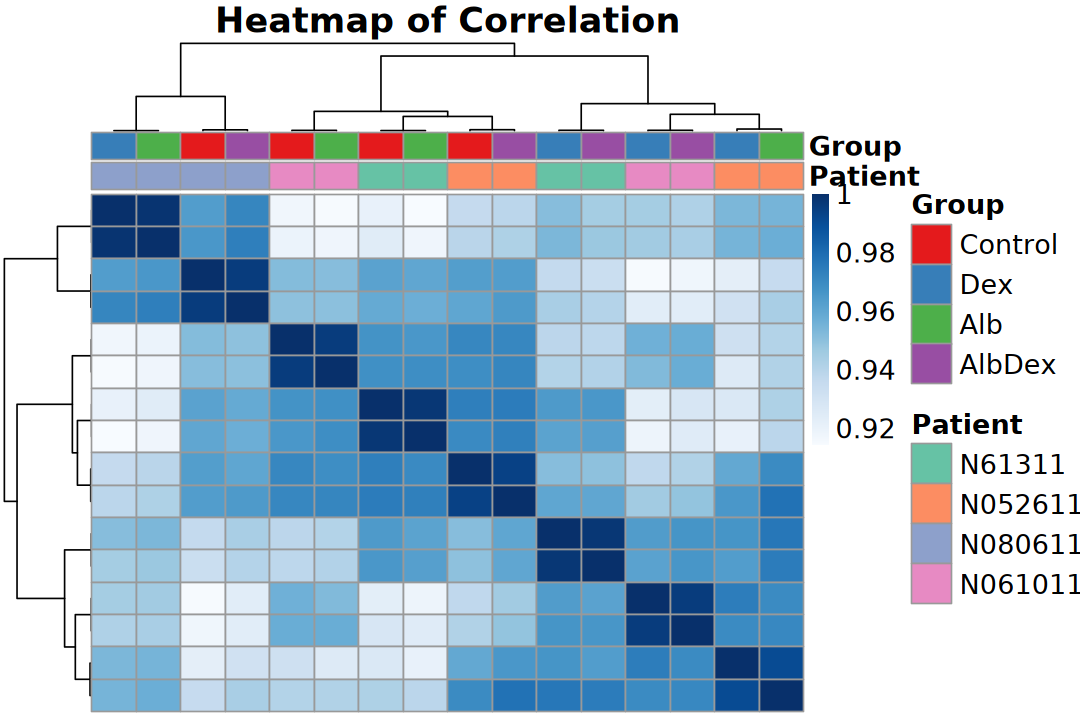

In [44]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(cor_mat), 
    clustering_distance_rows = "correlation",
    clustering_distance_cols = "correlation",
    annotation_col = ac, col = colors, 
    annotation_colors = anno_colors,
    main = "Heatmap of Correlation", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

## 7). Heatmap

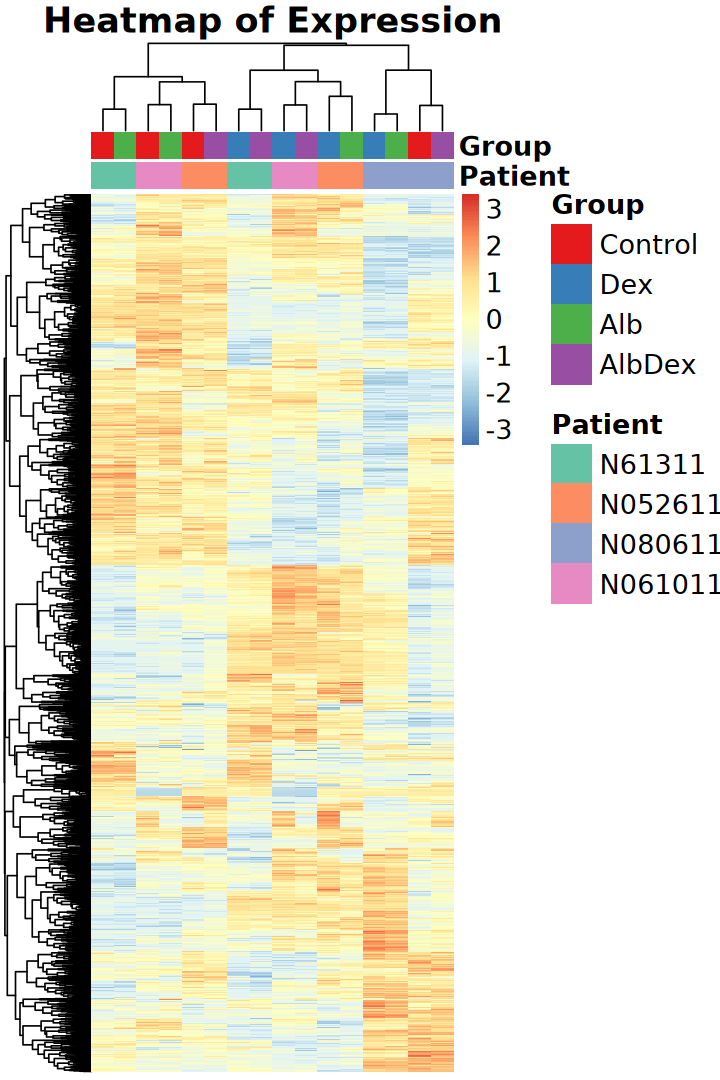

In [45]:
options(repr.plot.width = 6, repr.plot.height = 9)

pheatmap::pheatmap(
    norm_mat[top_var_idx, ], scale = "row", 
    annotation_col = ac, 
    annotation_colors = anno_colors, 
    main = "Heatmap of Expression", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

# 5. DEGs

In [46]:
logfc_cutoff <- log2(2)
p_cutoff <- 0.05

## 1). DESeq2

> median of ratios for normalization

In [47]:
design(dds) <- ~ 0 + Group + Patient
design(dds)

~0 + Group + Patient

In [48]:
dds <- DESeq(dds)

using pre-existing size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



In [49]:
resultsNames(dds)

[1] "GroupControl"   "GroupDex"       "GroupAlb"       "GroupAlbDex"   
[5] "PatientN052611" "PatientN080611" "PatientN061011"

In [50]:
contrast_pairs <- levels(dds$Group) |>
    combn(2, simplify = FALSE)
contrast_labels <- contrast_pairs |>
    map_chr(~ paste0(.x[2], "_vs_", .x[1]))
contrast_labels

[1] "Dex_vs_Control"    "Alb_vs_Control"    "AlbDex_vs_Control"
[4] "Alb_vs_Dex"        "AlbDex_vs_Dex"     "AlbDex_vs_Alb"

### a). Standard

In [51]:
deseq2_result_list <- map(contrast_pairs, function(lv) {
    results(dds, contrast = c("Group", lv[2], lv[1])) |>
        as.data.frame() |> 
        rownames_to_column("gene_id") |>
        dplyr::rename(logFC = log2FoldChange) |>
        mutate(
            method = "DESeq2",
            contrast = paste0(lv[2], "_vs_", lv[1]),
            result = case_when(
                padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
                padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
                TRUE ~ "NS"
            ) |> factor(levels = c("Up", "Down", "NS"))) |>
        left_join(
            rowData(dds) |> as.data.frame() |> 
                dplyr::select(symbol, type, basepairs) |>
                rownames_to_column("gene_id"), 
            by = "gene_id")
}) |> set_names(contrast_labels)

In [52]:
deseq2_result_df <- bind_rows(deseq2_result_list) |>
    group_by(contrast, result) |>
    arrange(padj, logFC |> abs() |> desc()) |>
    mutate(
        label = ifelse(
            type == "protein_coding" & 
                result %in% c("Up", "Down") & 
                row_number() <= 5, 
            symbol, NA_character_)) |>
    ungroup() |>
    mutate(contrast = factor(contrast, levels = contrast_labels))

table(deseq2_result_df$contrast, deseq2_result_df$result)

                   
                       Up  Down    NS
  Dex_vs_Control      568   570 16406
  Alb_vs_Control        4     0 17540
  AlbDex_vs_Control    15     0 17529
  Alb_vs_Dex            0     0 17544
  AlbDex_vs_Dex         2     0 17542
  AlbDex_vs_Alb         0     0 17544

### b). LFC Shrink

> Shrinkage of effect size (LFC estimates) is useful for visualization and ranking of genes.
>
> Notes:
> - `apeglm` shrunken LFC requires specific coefficients from resultsNames(dds). Re-leveling the reference group is necessary to compute contrasts not inherently present in the initial design matrix.

In [53]:
deseq2_lfc_result_list <- map(contrast_pairs, function(lv) {
    lfcShrink(dds, contrast = c("Group", lv[2], lv[1]), type = "ashr") |>
        as.data.frame() |> 
        rownames_to_column("gene_id") |>
        dplyr::rename(logFC = log2FoldChange) |>
        mutate(
            method = "DESeq2-lfcShrink",
            contrast = paste0(lv[2], "_vs_", lv[1]),
            result = case_when(
                padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
                padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
                TRUE ~ "NS"
            ) |> factor(levels = c("Up", "Down", "NS"))) |>
        left_join(
            rowData(dds) |> as.data.frame() |> 
                dplyr::select(symbol, type, basepairs) |>
                rownames_to_column("gene_id"), 
            by = "gene_id")
}) |> set_names(contrast_labels)

using 'ashr' for LFC shrinkage. If used in published research, please cite:
    Stephens, M. (2016) False discovery rates: a new deal. Biostatistics, 18:2.
    https://doi.org/10.1093/biostatistics/kxw041

using 'ashr' for LFC shrinkage. If used in published research, please cite:
    Stephens, M. (2016) False discovery rates: a new deal. Biostatistics, 18:2.
    https://doi.org/10.1093/biostatistics/kxw041

using 'ashr' for LFC shrinkage. If used in published research, please cite:
    Stephens, M. (2016) False discovery rates: a new deal. Biostatistics, 18:2.
    https://doi.org/10.1093/biostatistics/kxw041

using 'ashr' for LFC shrinkage. If used in published research, please cite:
    Stephens, M. (2016) False discovery rates: a new deal. Biostatistics, 18:2.
    https://doi.org/10.1093/biostatistics/kxw041

using 'ashr' for LFC shrinkage. If used in published research, please cite:
    Stephens, M. (2016) False discovery rates: a new deal. Biostatistics, 18:2.
    https://doi.org/

In [54]:
deseq2_lfc_result_df <- bind_rows(deseq2_lfc_result_list) |>
    group_by(contrast, result) |>
    arrange(padj, logFC |> abs() |> desc()) |>
    mutate(
        label = ifelse(
            type == "protein_coding" & 
                result %in% c("Up", "Down") & 
                row_number() <= 5, 
            symbol, NA_character_)) |>
    ungroup() |>
    mutate(contrast = factor(contrast, levels = contrast_labels))

table(deseq2_lfc_result_df$contrast, deseq2_lfc_result_df$result)

                   
                       Up  Down    NS
  Dex_vs_Control      196   159 17189
  Alb_vs_Control        3     0 17541
  AlbDex_vs_Control     5     0 17539
  Alb_vs_Dex            0     0 17544
  AlbDex_vs_Dex         1     0 17543
  AlbDex_vs_Alb         0     0 17544

## 2). edgeR

> Trimmed Mean of M-values (TMM)

In [55]:
design <- model.matrix(~ 0 + group + Patient, data = dgel$samples)
colnames(design)[1:nlevels((dgel$samples$group))] <- levels(dgel$samples$group)

In [56]:
contrast_pairs <- levels(dgel$samples$group) |>
    combn(2, simplify = FALSE)

contrast_labels <- contrast_pairs |>
    map_chr(~ paste0(.x[2], "_vs_", .x[1]))
contrast_labels

contrast_matrix <- contrast_pairs |> 
    map(function(lv) {paste0(lv[2], "-", lv[1])}) |>
    makeContrasts(contrasts = _, levels = design)
contrast_matrix

[1] "Dex_vs_Control"    "Alb_vs_Control"    "AlbDex_vs_Control"
[4] "Alb_vs_Dex"        "AlbDex_vs_Dex"     "AlbDex_vs_Alb"

,Dex-Control,Alb-Control,AlbDex-Control,Alb-Dex,AlbDex-Dex,AlbDex-Alb
Control,-1,-1,-1,0,0,0
Dex,1,0,0,-1,-1,0
Alb,0,1,0,1,0,-1
AlbDex,0,0,1,0,1,1
PatientN052611,0,0,0,0,0,0
PatientN080611,0,0,0,0,0,0
PatientN061011,0,0,0,0,0,0


### a). Negative binomial GLM framework

In [57]:
dgel <- estimateDisp(dgel, design)
# likelihood ratio test
fit <- glmFit(dgel, design)

In [58]:
edger_result_list <- map(colnames(contrast_matrix), function(idx) {
    glmLRT(fit, contrast = contrast_matrix[, idx]) |>
        topTags(n = Inf) |>
        as.data.frame() |>
        rownames_to_column("gene_id") |>
        dplyr::rename(padj = FDR, pvalue = PValue) |>
        mutate(
            method = "edgeR-lrt",
            contrast = gsub(idx, pattern = "-", replacement = "_vs_"),
            result = case_when(
                padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
                padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
                TRUE ~ "NS"
            ) |> factor(levels = c("Up", "Down", "NS")))
}) |> set_names(contrast_labels)

In [59]:
edger_result_df <- bind_rows(edger_result_list) |>
    group_by(contrast, result) |>
    arrange(padj, logFC |> abs() |> desc()) |>
    mutate(
        label = ifelse(
            type == "protein_coding" & 
                result %in% c("Up", "Down") & 
                row_number() <= 5, 
            symbol, NA_character_)) |>
    ungroup() |>
    mutate(contrast = factor(contrast, levels = contrast_labels))

table(edger_result_df$contrast, edger_result_df$result)

                   
                       Up  Down    NS
  Dex_vs_Control      599   662 16401
  Alb_vs_Control        7     2 17653
  AlbDex_vs_Control    17     3 17642
  Alb_vs_Dex            0     0 17662
  AlbDex_vs_Dex         1     1 17660
  AlbDex_vs_Alb         0     0 17662

### b). Quasi-likelihood pipeline (edgeR v3)

In [60]:
dgel <- estimateDisp(dgel, design)
# quasi-likelihood (QL) F-test
fit <- glmQLFit(dgel, design)

In [61]:
edger_qlf_result_list <- map(colnames(contrast_matrix), function(idx) {
    glmQLFTest(fit, contrast = contrast_matrix[, idx]) |>
        topTags(n = Inf) |>
        as.data.frame() |>
        rownames_to_column("gene_id") |>
        dplyr::rename(padj = FDR, pvalue = PValue) |>
        mutate(
            method = "edgeR",
            contrast = gsub(idx, pattern = "-", replacement = "_vs_"),
            result = case_when(
                padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
                padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
                TRUE ~ "NS"
            ) |> factor(levels = c("Up", "Down", "NS")))
}) |> set_names(contrast_labels)

In [62]:
edger_qlf_result_df <- bind_rows(edger_qlf_result_list) |>
    group_by(contrast, result) |>
    arrange(padj, logFC |> abs() |> desc()) |>
    mutate(
        label = ifelse(
            type == "protein_coding" & 
                result %in% c("Up", "Down") & 
                row_number() <= 5, 
            symbol, NA_character_)) |>
    ungroup() |>
    mutate(contrast = factor(contrast, levels = contrast_labels))

table(edger_qlf_result_df$contrast, edger_qlf_result_df$result)

                   
                       Up  Down    NS
  Dex_vs_Control      523   540 16599
  Alb_vs_Control        0     0 17662
  AlbDex_vs_Control     0     0 17662
  Alb_vs_Dex            0     0 17662
  AlbDex_vs_Dex         0     0 17662
  AlbDex_vs_Alb         0     0 17662

In [63]:
comparison_df <- edger_result_df |> 
    dplyr::select(gene_id, contrast, result_lrt = result) |> 
    inner_join(
        edger_qlf_result_df |> 
            dplyr::select(gene_id, contrast, result_qlf = result),
        by = c("gene_id", "contrast"))

comparison_df |> 
    group_split(contrast) |> 
    walk(function(sub_df) {
        cat("\n=========================================\n")
        cat("Contrast:", as.character(unique(sub_df$contrast)), "\n")
        cat("=========================================\n")
        print(table(LRT = sub_df$result_lrt, QLF = sub_df$result_qlf))
    })


Contrast: Dex_vs_Control 
      QLF
LRT       Up  Down    NS
  Up     518     0    81
  Down     0   532   130
  NS       5     8 16388

Contrast: Alb_vs_Control 
      QLF
LRT       Up  Down    NS
  Up       0     0     7
  Down     0     0     2
  NS       0     0 17653

Contrast: AlbDex_vs_Control 
      QLF
LRT       Up  Down    NS
  Up       0     0    17
  Down     0     0     3
  NS       0     0 17642

Contrast: Alb_vs_Dex 
      QLF
LRT       Up  Down    NS
  Up       0     0     0
  Down     0     0     0
  NS       0     0 17662

Contrast: AlbDex_vs_Dex 
      QLF
LRT       Up  Down    NS
  Up       0     0     1
  Down     0     0     1
  NS       0     0 17660

Contrast: AlbDex_vs_Alb 
      QLF
LRT       Up  Down    NS
  Up       0     0     0
  Down     0     0     0
  NS       0     0 17662


## 3). limma

> In the limma approach to RNA-seq, read counts are converted to log2-counts-per-million (logCPM), and the mean-variance relationship is modeled either with precision weights or with an empirical Bayes prior trend. The precision weights approach is called “voom,” and the prior trend approach is called “limma-trend.”

In [64]:
design <- model.matrix(~ 0 + group + Patient, data = dgel$samples)
colnames(design)[1:nlevels((dgel$samples$group))] <- levels(dgel$samples$group)

In [65]:
contrast_pairs <- levels(dgel$samples$group) |>
    combn(2, simplify = FALSE)

contrast_labels <- contrast_pairs |>
    map_chr(~ paste0(.x[2], "_vs_", .x[1]))
contrast_labels

contrast_matrix <- contrast_pairs |> 
    map(function(lv) {paste0(lv[2], "-", lv[1])}) |>
    makeContrasts(contrasts = _, levels = design)
contrast_matrix

[1] "Dex_vs_Control"    "Alb_vs_Control"    "AlbDex_vs_Control"
[4] "Alb_vs_Dex"        "AlbDex_vs_Dex"     "AlbDex_vs_Alb"

,Dex-Control,Alb-Control,AlbDex-Control,Alb-Dex,AlbDex-Dex,AlbDex-Alb
Control,-1,-1,-1,0,0,0
Dex,1,0,0,-1,-1,0
Alb,0,1,0,1,0,-1
AlbDex,0,0,1,0,1,1
PatientN052611,0,0,0,0,0,0
PatientN080611,0,0,0,0,0,0
PatientN061011,0,0,0,0,0,0


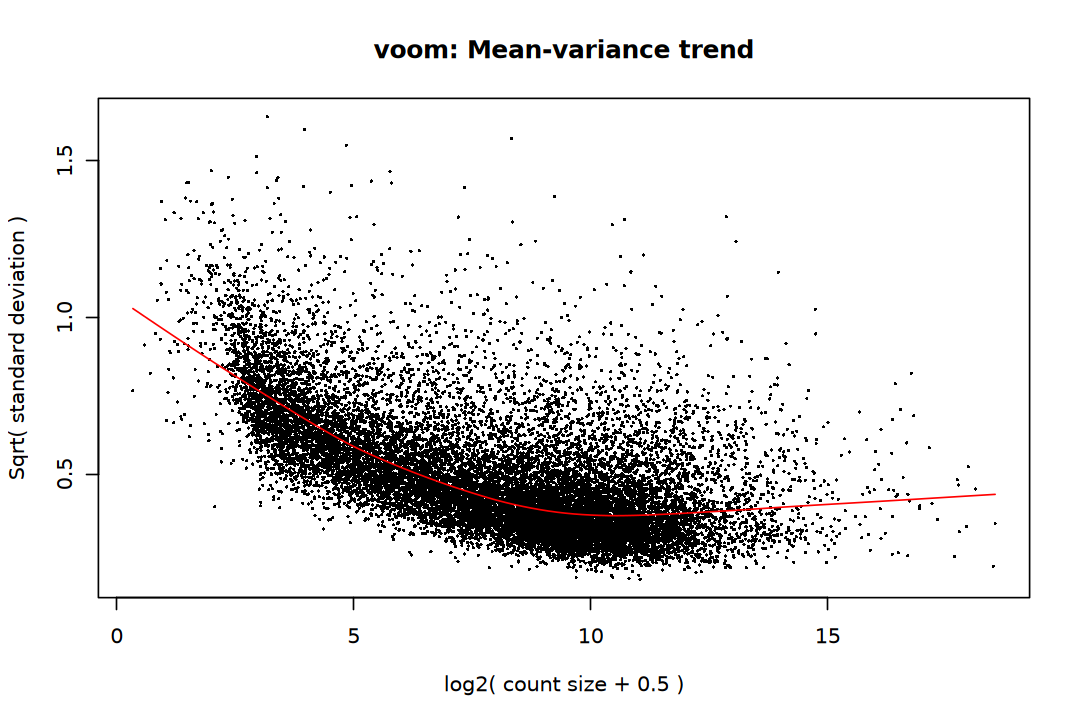

In [66]:
options(repr.plot.width = 9, repr.plot.height = 6)

norm_v <- voom(dgel, design, plot = TRUE)

In [67]:
# Linear Model for Series of Arrays
fit <- lmFit(norm_v, design)
# Compute contrasts from linear model fit
fit <- contrasts.fit(fit, contrast_matrix)
# Empirical Bayes Statistics for Differential Expression
fit <- eBayes(fit)

In [68]:
limma_result_list <- map(colnames(contrast_matrix), function(idx) {
    topTable(fit, coef = idx, number = Inf) |>
        as.data.frame() |>
        rownames_to_column("gene_id") |>
        dplyr::rename(padj = adj.P.Val, pvalue = P.Value) |>
        mutate(
            method = "limma",
            contrast = gsub(idx, pattern = "-", replacement = "_vs_"),
            result = case_when(
                padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
                padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
                TRUE ~ "NS"
            ) |> factor(levels = c("Up", "Down", "NS")))
}) |> set_names(contrast_labels)

In [69]:
limma_result_df <- bind_rows(limma_result_list) |>
    group_by(contrast, result) |>
    arrange(padj, logFC |> abs() |> desc()) |>
    mutate(
        label = ifelse(
            type == "protein_coding" & 
                result %in% c("Up", "Down") & 
                row_number() <= 5, 
            symbol, NA_character_)) |>
    ungroup() |>
    mutate(contrast = factor(contrast, levels = contrast_labels))

table(limma_result_df$contrast, limma_result_df$result)

                   
                       Up  Down    NS
  Dex_vs_Control      366   381 16915
  Alb_vs_Control        0     0 17662
  AlbDex_vs_Control     0     0 17662
  Alb_vs_Dex            0     0 17662
  AlbDex_vs_Dex         0     0 17662
  AlbDex_vs_Alb         0     0 17662

In [70]:
comparison_df <- edger_qlf_result_df |> 
    dplyr::select(gene_id, contrast, result_edger = result) |> 
    inner_join(
        limma_result_df |> 
            dplyr::select(gene_id, contrast, result_limma = result),
        by = c("gene_id", "contrast"))

comparison_df |> 
    group_split(contrast) |> 
    walk(function(sub_df) {
        cat("\n=========================================\n")
        cat("Contrast:", as.character(unique(sub_df$contrast)), "\n")
        cat("=========================================\n")
        print(table(edgeR = sub_df$result_edger, Limma = sub_df$result_limma))
    })


Contrast: Dex_vs_Control 
      Limma
edgeR     Up  Down    NS
  Up     358     0   165
  Down     0   373   167
  NS       8     8 16583

Contrast: Alb_vs_Control 
      Limma
edgeR     Up  Down    NS
  Up       0     0     0
  Down     0     0     0
  NS       0     0 17662

Contrast: AlbDex_vs_Control 
      Limma
edgeR     Up  Down    NS
  Up       0     0     0
  Down     0     0     0
  NS       0     0 17662

Contrast: Alb_vs_Dex 
      Limma
edgeR     Up  Down    NS
  Up       0     0     0
  Down     0     0     0
  NS       0     0 17662

Contrast: AlbDex_vs_Dex 
      Limma
edgeR     Up  Down    NS
  Up       0     0     0
  Down     0     0     0
  NS       0     0 17662

Contrast: AlbDex_vs_Alb 
      Limma
edgeR     Up  Down    NS
  Up       0     0     0
  Down     0     0     0
  NS       0     0 17662


# Reference

> 1. Law CW, Alhamdoosh M, Su S, Dong X, Tian L, Smyth GK, Ritchie ME (2018). “RNA-seq analysis is easy as 1-2-3 with limma, Glimma and edgeR.” F1000Research, 5, 1408. https://f1000research.com/articles/5-1408/v3. [RNA-seq analysis is easy as 1-2-3 with limma, Glimma and edgeR](https://www.bioconductor.org/packages/release/workflows/html/RNAseq123.html)
> 2. Law CW, Zeglinski K, Dong X, Alhamdoosh M, Smyth GK, Ritchie ME (2020). “A guide to creating design matrices for gene expression experiments.” F1000Research, 9, 1444. https://f1000research.com/articles/9-1444. [A guide to creating design matrices for gene expression experiments](https://www.bioconductor.org/packages/release/workflows/vignettes/RNAseq123/inst/doc/designmatrices.html)
> 2. Love MI, Anders S, Kim V, Huber W (2016). “RNA-Seq workflow: gene-level exploratory analysis and differential expression.” F1000Research. doi:10.12688/f1000research.7035.2. [RNA-seq workflow: gene-level exploratory analysis and differential expression](https://www.bioconductor.org/packages/release/workflows/html/rnaseqGene.html)
> 3. Chen Y, Lun ATL, Smyth GK (2016). “From reads to genes to pathways: differential expression analysis of RNA-Seq experiments using Rsubread and the edgeR quasi-likelihood pipeline.” F1000Research, 5, 1438. http://f1000research.com/articles/5-1438. [Gene-level RNA-seq differential expression and pathway analysis using Rsubread and the edgeR quasi-likelihood pipeline](https://www.bioconductor.org/packages/release/workflows/html/RnaSeqGeneEdgeRQL.html)